In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, classification_report

# Load the Telco churn dataset from your computer
print("Loading Telco churn dataset...")

# Option A – if the file is a CSV (most likely):
df = pd.read_csv("/Users/nicolomarseu/Downloads/WA_Fn-UseC_-Telco-Customer-Churn.xls")

# Option B – if it really is an Excel .xls file (needs: pip install xlrd):
# df = pd.read_excel("WA_Fn-UseC_-Telco-Customer-Churn.xls")

print(f"\nNumber of samples: {len(df)}")
print(f"Number of columns: {len(df.columns)}")
print(f"Column names: {list(df.columns)}")

print("\nFirst few rows:")
print(df.head())

print("\nDataset info:")
df.info()

print("\nTarget distribution:")
print(df['Churn'].value_counts())
print(f"Churned (Yes): {(df['Churn'] == 'Yes').sum()}")
print(f"Stayed (No): {(df['Churn'] == 'No').sum()}")

Loading Telco churn dataset...

Number of samples: 7043
Number of columns: 21
Column names: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

First few rows:
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phon

Churn
0    5174
1    1869
Name: count, dtype: int64

BASIC STATISTICS
       SeniorCitizen       tenure  MonthlyCharges  TotalCharges        Churn
count    7043.000000  7043.000000     7043.000000   7032.000000  7043.000000
mean        0.162147    32.371149       64.761692   2283.300441     0.265370
std         0.368612    24.559481       30.090047   2266.771362     0.441561
min         0.000000     0.000000       18.250000     18.800000     0.000000
25%         0.000000     9.000000       35.500000    401.450000     0.000000
50%         0.000000    29.000000       70.350000   1397.475000     0.000000
75%         0.000000    55.000000       89.850000   3794.737500     1.000000
max         1.000000    72.000000      118.750000   8684.800000     1.000000

MISSING VALUES
TotalCharges    11
dtype: int64

FEATURE DISTRIBUTIONS
Saved visualization to 'feature_distributions.png'


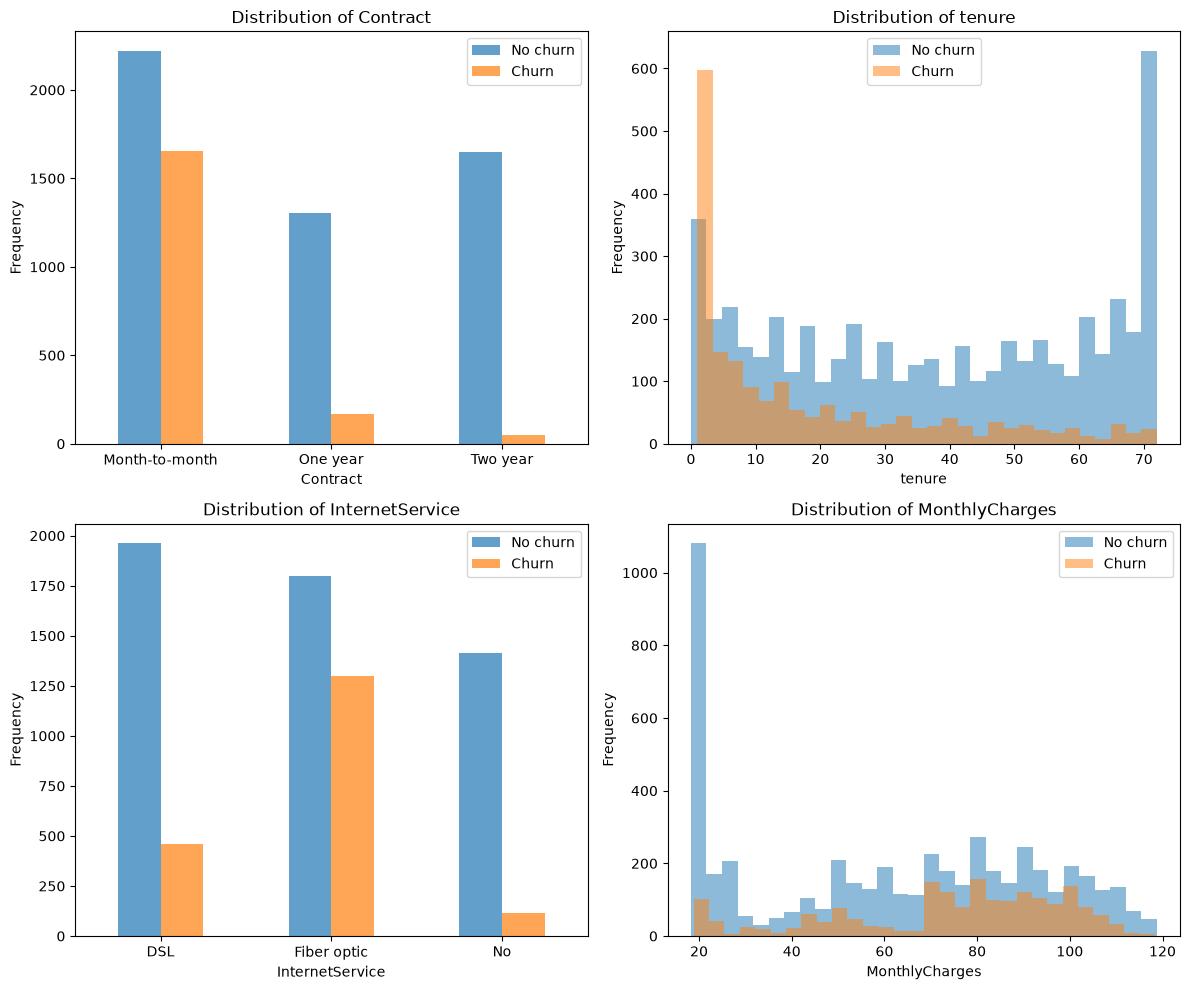

In [4]:
# --- Target setup ---
target = 'Churn'  # match your column name exactly

# Convert Yes/No to 1/0
df[target] = (
    df[target].astype(str).str.strip()
    .map({'No': 0, 'Yes': 1, '0': 0, '1': 1})
)
print(df[target].value_counts(dropna=False))

# TotalCharges is stored as text; blanks become NaN so the missing-value check finds them
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Basic statistics
print("\n" + "="*50)
print("BASIC STATISTICS")
print("="*50)
print(df.describe())  # numeric columns only; use df.describe(include='all') to see categoricals too

# Check for missing values
print("\n" + "="*50)
print("MISSING VALUES")
print("="*50)
missing = df.isnull().sum()
if missing.sum() == 0:
    print("✓ No missing values found!")
else:
    print(missing[missing > 0])

# Feature distributions
print("\n" + "="*50)
print("FEATURE DISTRIBUTIONS")
print("="*50)

key_features = ['Contract', 'tenure', 'InternetService', 'MonthlyCharges' ]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for idx, feature in enumerate(key_features):
    ax = axes[idx]

    if pd.api.types.is_numeric_dtype(df[feature]):
        # Numeric feature: overlapping histograms
        ax.hist(df[df[target] == 0][feature], alpha=0.5, label='No churn', bins=30)
        ax.hist(df[df[target] == 1][feature], alpha=0.5, label='Churn', bins=30)
        ax.legend()
    else:
        # Categorical feature: grouped bar chart
        counts = pd.crosstab(df[feature], df[target])
        counts.columns = ['No churn', 'Churn']
        counts.plot(kind='bar', ax=ax, alpha=0.7)
        ax.tick_params(axis='x', rotation=0)

    ax.set_xlabel(feature)
    ax.set_ylabel('Frequency')
    ax.set_title(f'Distribution of {feature}')

plt.tight_layout()
plt.savefig('feature_distributions.png', dpi=150, bbox_inches='tight')
print("Saved visualization to 'feature_distributions.png'")
plt.show()

In [5]:
print(df[target].dtype)
print(df[target].value_counts())

int64
Churn
0    5174
1    1869
Name: count, dtype: int64


In [6]:
from sklearn.preprocessing import StandardScaler

# --- Prep ---
# Drop the few rows where TotalCharges was blank
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df = df.dropna(subset=['TotalCharges'])

# Select the 5 features
features = ['Contract', 'tenure', 'InternetService', 'MonthlyCharges', 'PaperlessBilling']
X = df[features]
y = df[target]

# Turn text columns into 0/1 columns
X = pd.get_dummies(X, drop_first=True)

print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")

# --- Split ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# --- Scale ---
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)  # learn scaling from training data only
X_test = scaler.transform(X_test)        # apply the same scaling to test data

print("\n" + "="*50)
print("DATA SPLIT")
print("="*50)
print(f"Training set size: {X_train.shape[0]} samples")
print(f"Test set size: {X_test.shape[0]} samples")
print(f"Features after encoding: {X_train.shape[1]}")

print("\nTraining set target distribution:")
print(f"  No churn (0): {(y_train == 0).sum()} ({(y_train == 0).mean()*100:.1f}%)")
print(f"  Churn (1): {(y_train == 1).sum()} ({(y_train == 1).mean()*100:.1f}%)")

print("\nTest set target distribution:")
print(f"  No churn (0): {(y_test == 0).sum()} ({(y_test == 0).mean()*100:.1f}%)")
print(f"  Churn (1): {(y_test == 1).sum()} ({(y_test == 1).mean()*100:.1f}%)")

Features shape: (7032, 7)
Target shape: (7032,)

DATA SPLIT
Training set size: 5625 samples
Test set size: 1407 samples
Features after encoding: 7

Training set target distribution:
  No churn (0): 4130 (73.4%)
  Churn (1): 1495 (26.6%)

Test set target distribution:
  No churn (0): 1033 (73.4%)
  Churn (1): 374 (26.6%)


In [ ]:
# Create KNN classifier
# n_neighbors=50 means the model will look at the 50 nearest neighbors to make a prediction
 
knn = KNeighborsClassifier(n_neighbors=50)
knn.fit(X_train, y_train)
 
print("KNN classifier trained successfully!")
print(f"Number of neighbors (k): {knn.n_neighbors}")

KNN classifier trained successfully!
Number of neighbors (k): 5


In [9]:
y_train_pred = knn.predict(X_train)
y_test_pred = knn.predict(X_test)
 
print(f"\nTraining predictions: {len(y_train_pred)}")
print(f"Test predictions: {len(y_test_pred)}")


Training predictions: 5625
Test predictions: 1407


In [12]:
from sklearn.metrics import confusion_matrix, classification_report, f1_score, roc_auc_score

# Churn probabilities, then flag as churn if probability >= 0.4
threshold = 0.4
train_prob = knn.predict_proba(X_train)[:, 1]
test_prob = knn.predict_proba(X_test)[:, 1]
y_train_pred = (train_prob >= threshold).astype(int)
y_test_pred = (test_prob >= threshold).astype(int)

# Calculate metrics
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred)
test_recall = recall_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred)
test_auc = roc_auc_score(y_test, test_prob)
test_confusion = confusion_matrix(y_test, y_test_pred)

print("=== Model Performance ===")
print(f"\nTraining Accuracy: {train_accuracy:.4f} ({train_accuracy*100:.2f}%)")
print(f"Test Accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"Baseline Accuracy (always predict no churn): {(y_test == 0).mean():.4f}")
print(f"\nTest Precision: {test_precision:.4f}")
print(f"Test Recall: {test_recall:.4f}")
print(f"Test F1: {test_f1:.4f}")
print(f"Test ROC AUC: {test_auc:.4f}")

print("\n=== Confusion Matrix ===")
print("                    Predicted")
print("                 No churn   Churn")
print(f"Actual No churn    {test_confusion[0,0]:4d}      {test_confusion[0,1]:4d}")
print(f"       Churn       {test_confusion[1,0]:4d}      {test_confusion[1,1]:4d}")

print("\n=== Classification Report ===")
print(classification_report(y_test, y_test_pred, target_names=['No churn', 'Churn']))

=== Model Performance ===

Training Accuracy: 0.8116 (81.16%)
Test Accuracy: 0.7370 (73.70%)
Baseline Accuracy (always predict no churn): 0.7342

Test Precision: 0.5038
Test Recall: 0.7005
Test F1: 0.5861
Test ROC AUC: 0.7790

=== Confusion Matrix ===
                    Predicted
                 No churn   Churn
Actual No churn     775       258
       Churn        112       262

=== Classification Report ===
              precision    recall  f1-score   support

    No churn       0.87      0.75      0.81      1033
       Churn       0.50      0.70      0.59       374

    accuracy                           0.74      1407
   macro avg       0.69      0.73      0.70      1407
weighted avg       0.78      0.74      0.75      1407




EXPERIMENTING WITH DIFFERENT K VALUES
K= 1: Accuracy=0.7257, Precision=0.4842, Recall=0.4920, F1=0.4881
K= 3: Accuracy=0.7512, Precision=0.5351, Recall=0.4893, F1=0.5112
K= 5: Accuracy=0.7711, Precision=0.5798, Recall=0.5053, F1=0.5400
K= 7: Accuracy=0.7818, Precision=0.6098, Recall=0.4973, F1=0.5479
K= 9: Accuracy=0.7733, Precision=0.5896, Recall=0.4840, F1=0.5316
K=11: Accuracy=0.7719, Precision=0.5930, Recall=0.4519, F1=0.5129

Best K value: 7 (F1: 0.5479)
Baseline accuracy (always predict no churn): 0.7342

Saved visualization to 'knn_k_comparison.png'


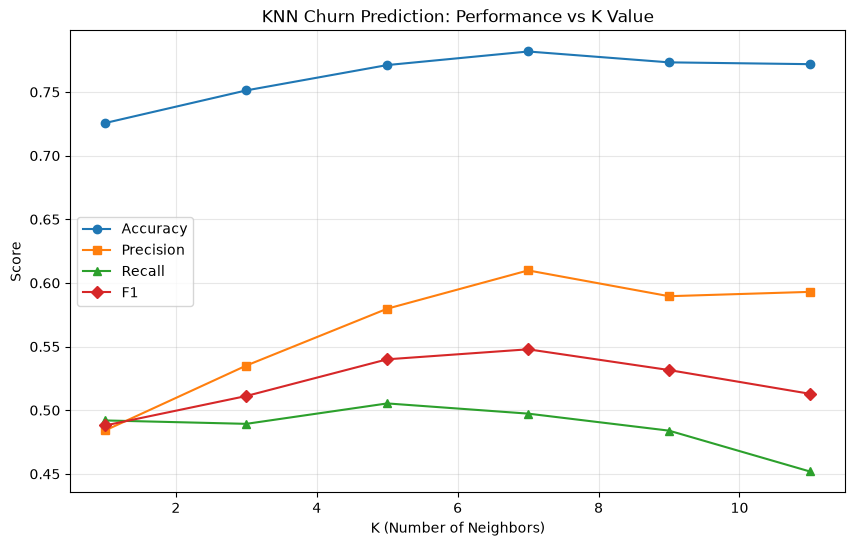

In [13]:
from sklearn.metrics import f1_score

# Experiment with different K values
print("\n" + "="*50)
print("EXPERIMENTING WITH DIFFERENT K VALUES")
print("="*50)

k_values = [1, 3, 5, 7, 9, 11]
results = []

for k in k_values:
    # Create and train model
    knn_temp = KNeighborsClassifier(n_neighbors=k)
    knn_temp.fit(X_train, y_train)

    # Make predictions
    y_pred_temp = knn_temp.predict(X_test)

    # Calculate metrics
    acc = accuracy_score(y_test, y_pred_temp)
    prec = precision_score(y_test, y_pred_temp)
    rec = recall_score(y_test, y_pred_temp)
    f1 = f1_score(y_test, y_pred_temp)

    results.append({
        'K': k,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1': f1
    })

    print(f"K={k:2d}: Accuracy={acc:.4f}, Precision={prec:.4f}, Recall={rec:.4f}, F1={f1:.4f}")

# Find best K (by F1, since churn is imbalanced)
results_df = pd.DataFrame(results)
best_k = results_df.loc[results_df['F1'].idxmax(), 'K']
print(f"\nBest K value: {best_k} (F1: {results_df['F1'].max():.4f})")
print(f"Baseline accuracy (always predict no churn): {(y_test == 0).mean():.4f}")

# Visualize results
plt.figure(figsize=(10, 6))
plt.plot(results_df['K'], results_df['Accuracy'], marker='o', label='Accuracy')
plt.plot(results_df['K'], results_df['Precision'], marker='s', label='Precision')
plt.plot(results_df['K'], results_df['Recall'], marker='^', label='Recall')
plt.plot(results_df['K'], results_df['F1'], marker='D', label='F1')
plt.xlabel('K (Number of Neighbors)')
plt.ylabel('Score')
plt.title('KNN Churn Prediction: Performance vs K Value')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('knn_k_comparison.png', dpi=150, bbox_inches='tight')
print("\nSaved visualization to 'knn_k_comparison.png'")
plt.show()